# Notebook 02 — Train the CAMP Latency Predictor

**Project:** Calibration-Aware ML-Predictive Scheduling for Single-GPU LLM Inference  
**Input:** `latency_dataset.csv` from Notebook 01  
**Models:** XGBoost Regressor and Random Forest Regressor  
**Target:** `engine_latency_s` (the admission-to-completion interval measured by Notebook 01)

## What this notebook does

1. Loads and checks the real CSV produced by Notebook 01.
2. Keeps successful requests and checks the target/features.
3. Splits by `run_id` so requests from the same workload run do not leak across train/calibration/test.
4. Trains XGBoost and Random Forest using the same input features.
5. Compares the predictors using grouped cross-validation and held-out test data.
6. Calculates an empirical 90th-percentile positive residual margin for a conservative latency estimate.
7. Saves the selected model, both comparison models, test predictions, metrics and metadata.

**No GUI.** All results are printed/displayed in notebook output cells.

> Important: Notebook 01 currently creates a small pilot dataset (about 180 requests across 9 runs). This is enough to test the pipeline, not to make a strong publication claim. The group-level test set will be small and its metrics may be unstable. Increase the number of independent runs and request volume before final experiments.

## 1. Install/import the training libraries

The predictor is tabular ML, so model training does not need the T4 GPU. We use CPU training to keep the notebook simple and avoid disturbing the vLLM GPU environment.

In [1]:
%pip -q install -U xgboost scikit-learn scipy joblib

import json
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import xgboost
from scipy.stats import spearmanr
from joblib import dump
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

SEED = 42
np.random.seed(SEED)

print("Python ML libraries loaded")
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

Python ML libraries loaded
scikit-learn: 1.9.1
XGBoost: 3.4.1


## 2. Load `latency_dataset.csv`

If the CSV is still in `/content`, the notebook loads it automatically. If you started a fresh Colab runtime or downloaded the CSV to your computer, the cell asks you to upload it.

In [2]:
DATA_DIR = Path("/content")

candidate_files = sorted(DATA_DIR.glob("*latency_dataset*.csv"))
if not candidate_files:
    try:
        from google.colab import files
        print("Upload the latency_dataset.csv downloaded from Notebook 01.")
        files.upload()
    except ImportError:
        raise FileNotFoundError(
            "Place latency_dataset.csv in /content or update DATA_DIR to its location."
        )
    candidate_files = sorted(DATA_DIR.glob("*latency_dataset*.csv"))

if not candidate_files:
    raise FileNotFoundError(
        "Could not find a file whose name contains 'latency_dataset'. "
        "Upload the CSV and rerun this cell."
    )

DATASET_PATH = candidate_files[0]
df_raw = pd.read_csv(DATASET_PATH)

print("Loaded:", DATASET_PATH)
print("Rows, columns:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
display(df_raw.head())

Upload the latency_dataset.csv downloaded from Notebook 01.


Saving latency_dataset.csv to latency_dataset.csv
Loaded: /content/latency_dataset.csv
Rows, columns: (180, 21)
Columns: ['request_id', 'run_id', 'workload_type', 'arrival_offset_s', 'prompt_text', 'prompt_tokens', 'max_output_tokens', 'arrival_rate_5s_rps', 'queue_depth_at_admission', 'active_requests_at_admission', 'concurrency_limit', 'gpu_utilization_pct', 'gpu_memory_used_mib', 'queue_wait_s', 'engine_latency_s', 'end_to_end_s', 'ttft_engine_s', 'actual_output_tokens', 'status', 'error', 'output_preview']


,request_id,run_id,workload_type,arrival_offset_s,prompt_text,prompt_tokens,max_output_tokens,arrival_rate_5s_rps,queue_depth_at_admission,active_requests_at_admission,...,gpu_utilization_pct,gpu_memory_used_mib,queue_wait_s,engine_latency_s,end_to_end_s,ttft_engine_s,actual_output_tokens,status,error,output_preview
0,steady_run_1_req_0000,steady_run_1,steady,0.0,Request reference steady_run_1_req_0000\nGive ...,2,32,5.000000,0,0,...,0.0,12381.0,0.000399,0.585622,0.586022,0.090379,32,completed,NaN,"I'm sorry, but I don't have enough context to ..."
1,steady_run_1_req_0001,steady_run_1,steady,0.6,Request reference steady_run_1_req_0001. The p...,2,32,3.324680,0,0,...,100.0,12381.0,0.000053,0.541665,0.541718,0.077919,32,completed,NaN,The system described involves managing large l...
2,steady_run_1_req_0002,steady_run_1,steady,1.2,Request reference steady_run_1_req_0002. Throu...,2,96,2.498401,0,0,...,100.0,12381.0,0.000033,1.604761,1.604794,0.130931,96,completed,NaN,"Throughput, tail latency, and goodput are cruc..."
3,steady_run_1_req_0003,steady_run_1,steady,1.8,Request reference steady_run_1_req_0003. An ad...,2,32,1.781632,1,0,...,100.0,12425.0,1.005651,0.510082,1.515733,0.047029,32,completed,NaN,An admission controller in an online inference...
4,steady_run_1_req_0004,steady_run_1,steady,2.4,Request reference steady_run_1_req_0004. Throu...,2,32,1.808815,1,0,...,100.0,12425.0,0.915412,0.543611,1.459023,0.079247,32,completed,NaN,"The throughput, tail latency, and goodput metr..."


## 3. Check data quality and prepare the target

The target is `engine_latency_s = completion_time - admission_time`, as recorded in Notebook 01. It is an end-to-end client-observed engine interval that includes local HTTP/client overhead and any internal vLLM queueing, prefill and decode. Do **not** describe it as pure GPU-kernel time.

In [3]:
TARGET = "engine_latency_s"
REQUIRED_COLUMNS = [
    "run_id", "status", TARGET,
    "prompt_tokens", "max_output_tokens",
    "queue_depth_at_admission", "active_requests_at_admission",
    "concurrency_limit"
]
missing_required = [c for c in REQUIRED_COLUMNS if c not in df_raw.columns]
if missing_required:
    raise ValueError(
        "CSV is missing required columns: " + ", ".join(missing_required) +
        "\nPlease use the latency_dataset.csv created by the current Notebook 01."
    )

print("Request status counts:")
display(df_raw["status"].value_counts(dropna=False).rename_axis("status").to_frame("count"))

# Train only on successful requests with finite, positive measured engine latency.
df = df_raw.copy()
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df[df["status"].astype(str).str.lower().eq("completed")].copy()
df = df[np.isfinite(df[TARGET]) & (df[TARGET] > 0)].copy()
df["run_id"] = df["run_id"].astype(str)

print("Usable successful rows:", len(df))
print("Independent run_id groups:", df["run_id"].nunique())
print("Target summary (seconds):")
display(df[TARGET].describe().to_frame().T)

if len(df) < 30:
    warnings.warn("Fewer than 30 successful examples: treat model scores as a pipeline smoke test only.")
if df["run_id"].nunique() < 5:
    raise ValueError("At least 5 distinct run_id groups are needed for the train/calibration/test split.")

if df["run_id"].nunique() < 9:
    warnings.warn("There are fewer than 9 independent runs. Group-held-out metrics may be highly variable.")

Request status counts:


,count
status,
completed,180


Usable successful rows: 180
Independent run_id groups: 9
Target summary (seconds):


,count,mean,std,min,25%,50%,75%,max
engine_latency_s,180.0,1.072659,0.403298,0.507419,0.672328,1.116504,1.319414,1.882343


## 4. Select features available at scheduling time

We exclude fields that are only known after generation (`actual_output_tokens`, completion time, measured latency, response text and status). `workload_type` is kept for analysis only, not used as a predictor feature. GPU telemetry is optional; missing values are imputed using statistics learned from the training partition only.

In [4]:
CANDIDATE_FEATURES = [
    "prompt_tokens",
    "max_output_tokens",
    "arrival_rate_5s_rps",
    "queue_depth_at_admission",
    "active_requests_at_admission",
    "concurrency_limit",
    "gpu_utilization_pct",
    "gpu_memory_used_mib",
]
FEATURES = [c for c in CANDIDATE_FEATURES if c in df.columns]

minimum_features = [
    "prompt_tokens", "max_output_tokens",
    "queue_depth_at_admission", "active_requests_at_admission",
    "concurrency_limit"
]
missing_minimum = [c for c in minimum_features if c not in FEATURES]
if missing_minimum:
    raise ValueError("Required predictor features missing: " + ", ".join(missing_minimum))

X = df[FEATURES].apply(pd.to_numeric, errors="coerce")
y = df[TARGET].astype(float)
groups = df["run_id"]

# Drop features that are entirely missing in the usable dataset.
all_missing = [c for c in FEATURES if X[c].isna().all()]
if all_missing:
    print("Dropping entirely missing features:", all_missing)
    X = X.drop(columns=all_missing)
    FEATURES = X.columns.tolist()

if X.shape[1] == 0:
    raise ValueError("No usable numeric features remain.")

print("Features used:", FEATURES)
print("Feature missingness (%):")
display((X.isna().mean() * 100).rename("missing_percent").to_frame())
print("Run groups by workload:")
if "workload_type" in df.columns:
    display(df.groupby(["workload_type", "run_id"], dropna=False).size().rename("rows").reset_index())
else:
    display(df.groupby("run_id").size().rename("rows").reset_index())

Features used: ['prompt_tokens', 'max_output_tokens', 'arrival_rate_5s_rps', 'queue_depth_at_admission', 'active_requests_at_admission', 'concurrency_limit', 'gpu_utilization_pct', 'gpu_memory_used_mib']
Feature missingness (%):


,missing_percent
prompt_tokens,0.0
max_output_tokens,0.0
arrival_rate_5s_rps,0.0
queue_depth_at_admission,0.0
active_requests_at_admission,0.0
concurrency_limit,0.0
gpu_utilization_pct,0.0
gpu_memory_used_mib,0.0


Run groups by workload:


,workload_type,run_id,rows
0,bursty,bursty_run_1,20
1,bursty,bursty_run_2,20
2,bursty,bursty_run_3,20
3,mixed,mixed_run_1,20
4,mixed,mixed_run_2,20
5,mixed,mixed_run_3,20
6,steady,steady_run_1,20
7,steady,steady_run_2,20
8,steady,steady_run_3,20


## 5. Split by entire workload runs

A random row split would place requests from the same run in both training and testing. Those requests share arrival patterns and system state. Instead, this notebook holds out complete `run_id` groups for calibration and final testing.

In [5]:
# First hold out approximately 20% of run groups for the final test set.
outer_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(outer_split.split(X, y, groups=groups))

# Split the development data again: approximately 20% of all data for calibration.
X_dev = X.iloc[dev_idx]
y_dev = y.iloc[dev_idx]
g_dev = groups.iloc[dev_idx]
inner_split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED + 1)
train_rel_idx, cal_rel_idx = next(inner_split.split(X_dev, y_dev, groups=g_dev))

train_idx = dev_idx[train_rel_idx]
cal_idx = dev_idx[cal_rel_idx]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_cal, y_cal = X.iloc[cal_idx], y.iloc[cal_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
g_train, g_cal, g_test = groups.iloc[train_idx], groups.iloc[cal_idx], groups.iloc[test_idx]

# Explicit leakage check: no run_id may occur in more than one partition.
train_groups, cal_groups, test_groups = set(g_train), set(g_cal), set(g_test)
assert train_groups.isdisjoint(cal_groups)
assert train_groups.isdisjoint(test_groups)
assert cal_groups.isdisjoint(test_groups)

print(f"Train: {len(X_train)} rows / {len(train_groups)} runs")
print(f"Calibration: {len(X_cal)} rows / {len(cal_groups)} runs")
print(f"Test: {len(X_test)} rows / {len(test_groups)} runs")
print("Train run IDs:", sorted(train_groups))
print("Calibration run IDs:", sorted(cal_groups))
print("Test run IDs:", sorted(test_groups))

if min(len(train_groups), len(cal_groups), len(test_groups)) < 1:
    raise ValueError("A partition has no run groups. Collect more independent runs in Notebook 01.")
if len(train_groups) < 3:
    warnings.warn("Very few training run groups: cross-validation and performance estimates will be noisy.")

Train: 100 rows / 5 runs
Calibration: 40 rows / 2 runs
Test: 40 rows / 2 runs
Train run IDs: ['bursty_run_1', 'bursty_run_3', 'mixed_run_1', 'mixed_run_3', 'steady_run_3']
Calibration run IDs: ['mixed_run_2', 'steady_run_1']
Test run IDs: ['bursty_run_2', 'steady_run_2']


## 6. Define the two regression models

Both models use the same median imputation pipeline and identical feature columns. Tree-based models do not require feature scaling. XGBoost is the primary candidate; Random Forest is a comparison baseline.

In [6]:
def make_pipeline(model):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("regressor", model)
    ])

models = {
    "XGBoost": make_pipeline(
        XGBRegressor(
            objective="reg:squarederror",
            n_estimators=300,
            max_depth=4,
            learning_rate=0.04,
            subsample=0.85,
            colsample_bytree=0.90,
            reg_lambda=2.0,
            random_state=SEED,
            n_jobs=-1,
            tree_method="hist"
        )
    ),
    "Random Forest": make_pipeline(
        RandomForestRegressor(
            n_estimators=350,
            max_depth=None,
            min_samples_leaf=2,
            max_features=1.0,
            random_state=SEED,
            n_jobs=-1
        )
    )
}

print("Models:", list(models.keys()))

Models: ['XGBoost', 'Random Forest']


## 7. Compare models using grouped cross-validation

Cross-validation runs only inside the training partition. Complete `run_id` groups remain together in each fold. We select the model with the lowest mean cross-validated MAE; the final test set is not used for model selection.

In [7]:
n_train_groups = g_train.nunique()
n_splits = min(3, n_train_groups)
if n_splits < 2:
    raise ValueError("Need at least 2 training run groups for GroupKFold.")
cv = GroupKFold(n_splits=n_splits)

cv_rows = []
for name, pipe in models.items():
    scores = cross_val_score(
        pipe, X_train, y_train,
        groups=g_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )
    mae_scores = -scores
    cv_rows.append({
        "model": name,
        "group_cv_MAE_mean_s": float(mae_scores.mean()),
        "group_cv_MAE_std_s": float(mae_scores.std(ddof=1)) if len(mae_scores) > 1 else 0.0
    })

cv_results = pd.DataFrame(cv_rows).sort_values("group_cv_MAE_mean_s").reset_index(drop=True)
display(cv_results.round(4))
selected_name = str(cv_results.iloc[0]["model"])
print("Selected using training-only grouped CV:", selected_name)

,model,group_cv_MAE_mean_s,group_cv_MAE_std_s
0,Random Forest,0.1862,0.0199
1,XGBoost,0.2423,0.0435


Selected using training-only grouped CV: Random Forest


## 8. Fit both models and compare on the held-out test set

This is the final comparison on unseen run groups. The test metrics are for this pilot dataset and must not be presented as general performance guarantees.

In [8]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    result = {
        "MAE_s": mean_absolute_error(y_true, y_pred),
        "RMSE_s": math.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred) if len(y_true) >= 2 else np.nan,
    }
    if len(y_true) >= 2 and np.std(y_true) > 0 and np.std(y_pred) > 0:
        result["Spearman_rho"] = float(spearmanr(y_true, y_pred).statistic)
    else:
        result["Spearman_rho"] = np.nan
    return result

fitted_models = {}
test_predictions = {}
test_metric_rows = []

for name, pipe in models.items():
    fitted = clone(pipe)
    fitted.fit(X_train, y_train)
    pred = np.maximum(0.0, fitted.predict(X_test))
    fitted_models[name] = fitted
    test_predictions[name] = pred
    row = {"model": name, **regression_metrics(y_test, pred)}
    test_metric_rows.append(row)

test_metrics = pd.DataFrame(test_metric_rows).sort_values("MAE_s").reset_index(drop=True)
print("Held-out test performance (seconds unless stated):")
display(test_metrics.round(4))

# A simple median predictor is included as a sanity-check baseline.
median_pred = np.full(len(y_test), float(y_train.median()))
print("Training-median baseline:", regression_metrics(y_test, median_pred))

Held-out test performance (seconds unless stated):


,model,MAE_s,RMSE_s,R2,Spearman_rho
0,Random Forest,0.1155,0.1548,0.8391,0.8588
1,XGBoost,0.1266,0.1700,0.8058,0.8542


Training-median baseline: {'MAE_s': 0.3428246680000143, 'RMSE_s': 0.4194188601499861, 'R2': -0.18172193640587864, 'Spearman_rho': nan}


## 9. Calibrate a conservative latency estimate

The selected predictor produces a point estimate. We calculate a one-sided empirical residual margin on the separate calibration runs: `margin = 90th percentile(actual - predicted)`. The scheduler can use `predicted_latency + margin` as a conservative estimate.

This is an empirical pilot calibration margin, **not a formal coverage guarantee**: requests within a run are correlated, the number of independent runs is small, and workload drift can invalidate the margin. Notebook 03 must report actual coverage on unseen test data.

In [9]:
selected_model = fitted_models[selected_name]
cal_pred = np.maximum(0.0, selected_model.predict(X_cal))
cal_residuals = y_cal.to_numpy(dtype=float) - cal_pred

# Finite-sample adjusted quantile level for a one-sided 90% residual margin.
alpha = 0.10
n_cal = len(cal_residuals)
q_level = min(1.0, math.ceil((n_cal + 1) * (1 - alpha)) / n_cal)
residual_margin = max(0.0, float(np.quantile(cal_residuals, q_level, method="higher")))

print("Selected model:", selected_name)
print("Calibration rows:", n_cal)
print("Residual quantile level used:", round(q_level, 4))
print("Conservative residual margin (seconds):", round(residual_margin, 4))

selected_test_pred = test_predictions[selected_name]
upper_test_pred = selected_test_pred + residual_margin
empirical_test_coverage = float(np.mean(y_test.to_numpy() <= upper_test_pred))
print("Held-out test coverage of calibrated upper estimate:", round(empirical_test_coverage, 4))
print("Held-out test underprediction rate of point estimate:",
      round(float(np.mean(y_test.to_numpy() > selected_test_pred)), 4))

Selected model: Random Forest
Calibration rows: 40
Residual quantile level used: 0.925
Conservative residual margin (seconds): 0.2434
Held-out test coverage of calibrated upper estimate: 0.975
Held-out test underprediction rate of point estimate: 0.375


## 10. Inspect actual vs predicted latency

A scatter plot close to the diagonal indicates more accurate predictions. Also inspect error by workload: a model can have reasonable overall MAE while performing poorly under bursty arrivals.

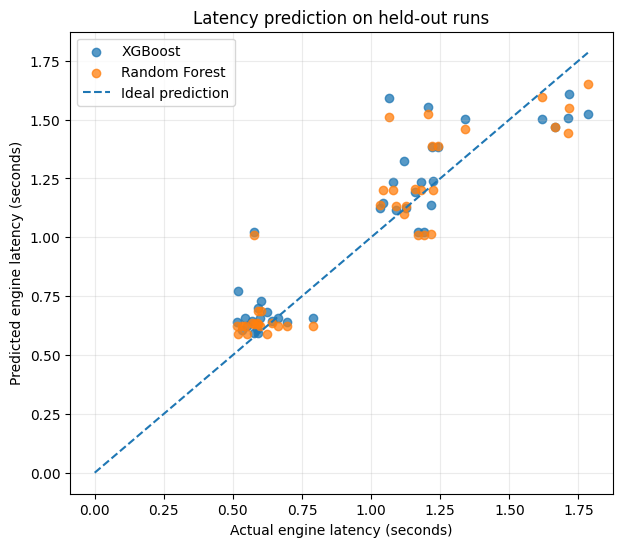

Test error by workload:


,requests,MAE_s,mean_actual_s,mean_predicted_s
workload_type,,,,
bursty,20,0.1026,1.0230,1.0441
steady,20,0.1284,0.9251,0.9662


In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
for name, pred in test_predictions.items():
    ax.scatter(y_test, pred, alpha=0.75, label=name)
upper = max(float(y_test.max()), max(float(np.max(p)) for p in test_predictions.values()))
ax.plot([0, upper], [0, upper], linestyle="--", label="Ideal prediction")
ax.set_xlabel("Actual engine latency (seconds)")
ax.set_ylabel("Predicted engine latency (seconds)")
ax.set_title("Latency prediction on held-out runs")
ax.legend()
ax.grid(True, alpha=0.25)
plt.show()

selected_test_rows = df.loc[X_test.index, ["run_id", "workload_type"]].copy() if "workload_type" in df.columns else df.loc[X_test.index, ["run_id"]].copy()
selected_test_rows["actual_engine_latency_s"] = y_test.to_numpy()
selected_test_rows["predicted_engine_latency_s"] = selected_test_pred
selected_test_rows["calibrated_upper_latency_s"] = upper_test_pred
selected_test_rows["absolute_error_s"] = np.abs(y_test.to_numpy() - selected_test_pred)
print("Test error by workload:")
if "workload_type" in selected_test_rows.columns:
    display(selected_test_rows.groupby("workload_type").agg(
        requests=("actual_engine_latency_s", "count"),
        MAE_s=("absolute_error_s", "mean"),
        mean_actual_s=("actual_engine_latency_s", "mean"),
        mean_predicted_s=("predicted_engine_latency_s", "mean")
    ).round(4))
else:
    display(selected_test_rows.head())

## 11. Save trained models and experiment outputs

The files are written to `/content/camp_model_outputs/`. Download them or copy them to Google Drive before the Colab runtime ends. Notebook 03 will load the selected model and its metadata.

In [11]:
OUTPUT_DIR = Path("/content/camp_model_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save both comparison models and the selected model separately.
for name, fitted in fitted_models.items():
    safe_name = name.lower().replace(" ", "_")
    dump(fitted, OUTPUT_DIR / f"{safe_name}_latency_pipeline.joblib")

dump(selected_model, OUTPUT_DIR / "camp_latency_predictor.joblib")

# Save predictions for final analysis and reproducibility.
prediction_output = selected_test_rows.copy()
prediction_output.to_csv(OUTPUT_DIR / "predictor_test_predictions.csv", index=False)
cv_results.to_csv(OUTPUT_DIR / "predictor_group_cv_results.csv", index=False)
test_metrics.to_csv(OUTPUT_DIR / "predictor_test_metrics.csv", index=False)

metadata = {
    "project": "CAMP - Calibration-Aware ML-Predictive Scheduling",
    "target": TARGET,
    "target_definition": "completion_time - admission_time as recorded by Notebook 01; client-observed engine interval, not pure GPU compute time",
    "features": FEATURES,
    "selected_model": selected_name,
    "selected_model_file": "camp_latency_predictor.joblib",
    "calibration_method": "one-sided empirical 90th-percentile residual margin on run-held-out calibration partition",
    "calibration_residual_margin_s": residual_margin,
    "calibration_quantile_level": q_level,
    "calibration_rows": int(len(X_cal)),
    "test_coverage": empirical_test_coverage,
    "train_run_ids": sorted(train_groups),
    "calibration_run_ids": sorted(cal_groups),
    "test_run_ids": sorted(test_groups),
    "seed": SEED,
    "scikit_learn_version": sklearn.__version__,
    "xgboost_version": xgboost.__version__,
    "warning": "Pilot results only. Residual calibration is empirical, not a formal guarantee; validate on more independent workload runs and under distribution shift."
}
(OUTPUT_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))

print("Saved model and outputs in:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{path.name:45s} {path.stat().st_size/1024:8.1f} KB")

Saved model and outputs in: /content/camp_model_outputs
camp_latency_predictor.joblib                   1362.0 KB
model_metadata.json                                1.3 KB
predictor_group_cv_results.csv                     0.1 KB
predictor_test_metrics.csv                         0.2 KB
predictor_test_predictions.csv                     3.9 KB
random_forest_latency_pipeline.joblib           1362.0 KB
xgboost_latency_pipeline.joblib                  450.9 KB


## 12. Download the artifacts

Download the selected model, metadata, comparison metrics and test predictions. Keep the model and metadata together; Notebook 03 needs both.

In [12]:
from google.colab import files

for filename in [
    "camp_latency_predictor.joblib",
    "model_metadata.json",
    "predictor_test_metrics.csv",
    "predictor_group_cv_results.csv",
    "predictor_test_predictions.csv"
]:
    path = OUTPUT_DIR / filename
    if path.exists():
        files.download(str(path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Notebook 02 completion checklist

- [ ] `latency_dataset.csv` loaded successfully.
- [ ] Only completed requests with valid positive `engine_latency_s` used for training.
- [ ] Features contain only information available at admission time.
- [ ] Train, calibration and test partitions have disjoint `run_id` values.
- [ ] XGBoost and Random Forest trained and compared.
- [ ] Grouped cross-validation used for model selection.
- [ ] Calibration margin and test coverage reported.
- [ ] Model, metadata and CSV outputs saved.

### What comes next

Notebook 03 uses `benchmark_traces.csv` (the independent requests reserved by Notebook 01), the selected model and its calibration margin to compare FIFO, Fixed-K, Heuristic Adaptive and CAMP ML-Predictive scheduling. Keep the benchmark trace separate from the predictor training data.